# LEAF-1/FIRE motif enrichment against HOMER on cCREs

Reads tables from `../data/` and writes figures to `../output/`.
Source analysis: `../../NOTEBOOK_PROVENANCE.tsv`.

Per motif, the LEAF-1/FIRE enrichment score (log10 motif z) against the
conventional HOMER enrichment on the cell type's cCREs, with the other cell
types' cCREs as background (the source figures' "celltype_only" version). HOMER
effect size is log2(% target / % background); significant at q < 0.05.

Which motifs can appear: the FIRE table holds significant motifs only, so every
point here is FIRE-significant, and a point needs a HOMER result for the same
motif. Points are therefore either significant in both or in LEAF-1/FIRE only;
the motifs significant in HOMER only (178 for club cells, 122 for atrial
cardiomyocytes) have no FIRE score and cannot be drawn. The source figures'
legend listed "neither" and "homer_only" classes that never contain a point; they
are dropped here.

Each panel gives the Spearman correlation of the two plotted axes. The
source summary (`per_target_summary.tsv`) correlates the FIRE score with the
HOMER -log10 P instead (club 0.13, P = 0.23; atrial 0.09, P = 0.44); the last
cell prints both. Labelled TFs are the ones the source figures labelled.

Against the source figures: one two-panel figure; LEAF-1/FIRE-only points in
LEAF-1 blue (were red); cell-type names without underscores; empty legend
classes removed.

Panel:
- `scatac_motif_fire_vs_homer`: a, club cell; b, atrial cardiomyocyte.

In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from notebook/, from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA.relative_to(_p))
print("OUT :", OUT.relative_to(_p))

DATA: scatac/data
OUT : scatac/output


In [2]:
# ── Constants and data ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr

PANELS = [("Club_Cell", "Club cell", ["FOXA3", "SOX10"]),
          ("Atrial_Cardiomyocyte", "Atrial cardiomyocyte", ["ELK4"])]
Q = 0.05
CLASSES = [("both", "Significant in LEAF-1/FIRE and HOMER", "#999999"),
           ("fire_only", "Significant in LEAF-1/FIRE only", OKABE_ITO["blue"])]
PANEL_RC = {"font.size": 6, "axes.titlesize": 7, "axes.labelsize": 6.5,
            "xtick.labelsize": 6, "ytick.labelsize": 6, "legend.fontsize": 6}

d = pd.read_csv(DATA / "scatac_motif_fire_vs_homer.csv", float_precision="round_trip")
assert set(d.bg_mode) == {"celltype"}
pts = d.dropna(subset=["fire_score", "homer_log2fc"]).copy()
assert pts.fire_significant.eq(True).all()          # the FIRE table is significant-only
pts["x"] = np.log10(pts.fire_score)
pts["cls"] = np.where(pts.homer_qval < Q, "both", "fire_only")
print(pts.groupby(["target", "cls"]).size().unstack().to_string())

cls                   both  fire_only
target                               
Atrial_Cardiomyocyte    26         51
Club_Cell               60         28


saved: scatac/output/scatac_motif_fire_vs_homer.pdf
saved: scatac/output/scatac_motif_fire_vs_homer.png
saved: scatac/output/scatac_motif_fire_vs_homer.svg
saved: scatac/output/scatac_motif_fire_vs_homer.tsv


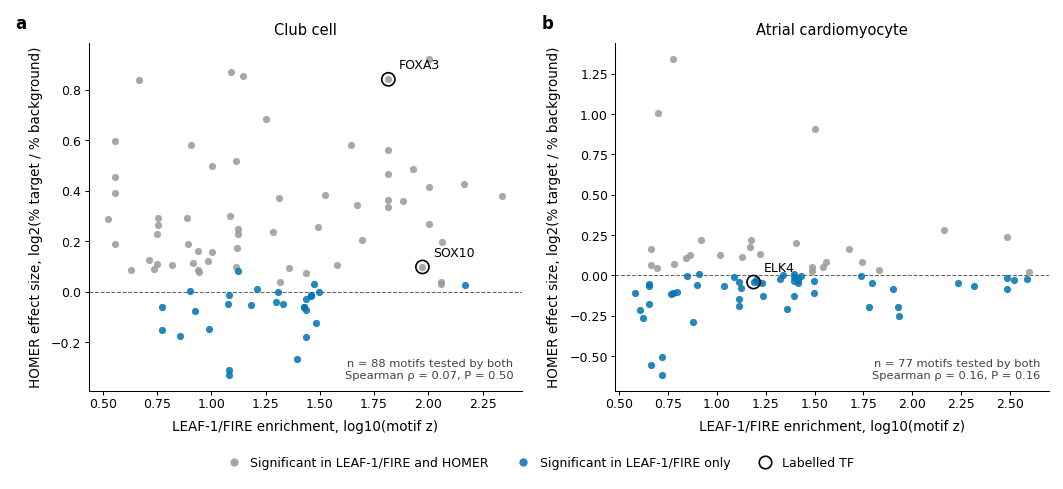

In [3]:
# ── Figure ─────────────────────────────────────────────────────────────────────
with plt.rc_context(PANEL_RC):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.2))
    stats = []
    for ax, (target, title, highlight), letter in zip(axes, PANELS, "ab"):
        p = pts[pts.target == target]
        for cls, _, color in CLASSES:
            s = p[p.cls == cls]
            ax.scatter(s.x, s.homer_log2fc, s=12, color=color, alpha=0.85, linewidth=0, zorder=3)
        for gene in highlight:
            r = p[p.gene == gene].iloc[0]
            ax.scatter([r.x], [r.homer_log2fc], s=40, facecolor="none", edgecolor="black",
                       linewidth=0.8, zorder=4)
            ax.annotate(gene, (r.x, r.homer_log2fc), xytext=(5, 5), textcoords="offset points",
                        fontsize=6, zorder=5)
        ax.axhline(0, color="#666666", ls="--", lw=0.5, zorder=1)
        rho = spearmanr(p.x, p.homer_log2fc)
        stats.append((title, len(p), rho.statistic, rho.pvalue))
        ax.text(0.98, 0.03, f"n = {len(p)} motifs tested by both\n"
                            f"Spearman \u03c1 = {rho.statistic:.2f}, P = {rho.pvalue:.2f}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=5.5, color="#444444")
        ax.set_title(title, pad=4)
        ax.set_xlabel("LEAF-1/FIRE enrichment, log10(motif z)")
        ax.set_ylabel("HOMER effect size, log2(% target / % background)")
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(axis="both", length=2, pad=1.5, width=0.5)
        ax.text(-0.17, 1.03, letter, transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")
    handles = [Line2D([], [], ls="", marker="o", ms=4, mfc=c, mec="none", alpha=0.85, label=lab)
               for _, lab, c in CLASSES]
    handles.append(Line2D([], [], ls="", marker="o", ms=6, mfc="none", mec="black", mew=0.8,
                          label="Labelled TF"))
    fig.tight_layout(rect=(0, 0.07, 1, 1), w_pad=2.0)
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False,
               bbox_to_anchor=(0.5, 0.0), columnspacing=1.8, handletextpad=0.3)
    out = pts[["target", "gene", "fire_score", "x", "fire_pearson", "homer_log2fc",
               "homer_neglog10p", "homer_qval", "cls"]].rename(columns={"x": "log10_fire_score"})
    savefig(fig, OUT, "scatac_motif_fire_vs_homer", data=out.sort_values(["target", "gene"]))
    plt.show()

In [4]:
# ── Numbers for the figure legend ─────────────────────────────────────────────
for title, n, r, pv in stats:
    print(f"{title}: n = {n}, Spearman rho (plotted axes) = {r:.3f}, P = {pv:.3g}")
for target, title, _ in PANELS:
    p = pts[pts.target == target]
    r = spearmanr(p.fire_score, p.homer_neglog10p)
    print(f"{title}: FIRE score vs HOMER -log10 P (source summary): rho = {r.statistic:.3f}, P = {r.pvalue:.3g}")
    allg = d[d.target == target]
    print(f"   FIRE-significant {int(allg.fire_significant.eq(True).sum())}, HOMER q<{Q} "
          f"{int((allg.homer_qval < Q).sum())}, both {int(((allg.fire_significant == True) & (allg.homer_qval < Q)).sum())}, "
          f"HOMER-only {int(((allg.fire_significant != True) & (allg.homer_qval < Q)).sum())}")

Club cell: n = 88, Spearman rho (plotted axes) = 0.073, P = 0.501
Atrial cardiomyocyte: n = 77, Spearman rho (plotted axes) = 0.162, P = 0.16
Club cell: FIRE score vs HOMER -log10 P (source summary): rho = 0.130, P = 0.227
   FIRE-significant 282, HOMER q<0.05 238, both 60, HOMER-only 178
Atrial cardiomyocyte: FIRE score vs HOMER -log10 P (source summary): rho = 0.090, P = 0.437
   FIRE-significant 253, HOMER q<0.05 148, both 26, HOMER-only 122
